In [1]:
%pip install qiskit qiskit-aer matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

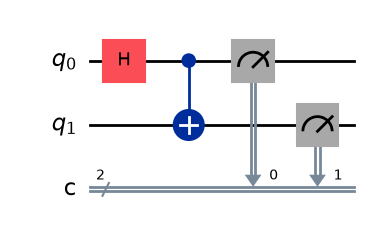

In [3]:
# Create a circuit with 2 qubits and 2 classical bits
qc_original = QuantumCircuit(2, 2)

# Create a superposition on qubit 0
qc_original.h(0)

# Entangle qubit 0 and qubit 1
qc_original.cx(0, 1)

# Measure both qubits
qc_original.measure([0, 1], [0, 1])

# Display the circuit
qc_original.draw('mpl')

In [4]:
print("Prediction for the original Bell circuit:")
print("00: approximately 50%")
print("11: approximately 50%")
print("01: approximately 0%")
print("10: approximately 0%")

Prediction for the original Bell circuit:
00: approximately 50%
11: approximately 50%
01: approximately 0%
10: approximately 0%


In [5]:
simulator = AerSimulator()

job_original = simulator.run(qc_original, shots=100)
result_original = job_original.result()

counts_original = result_original.get_counts()

print("Original circuit results:", counts_original)
print("Total shots:", sum(counts_original.values()))

Original circuit results: {'00': 57, '11': 43}
Total shots: 100


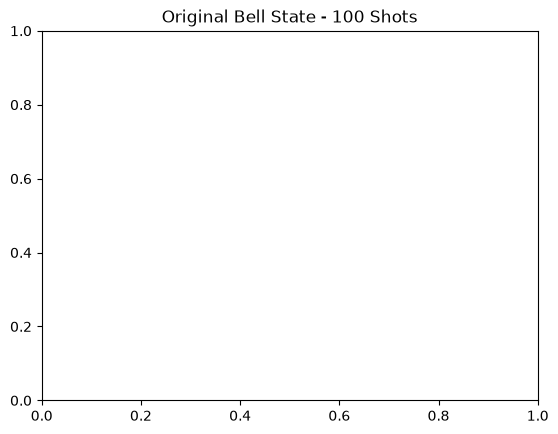

In [6]:
plot_histogram(counts_original)
plt.title("Original Bell State - 100 Shots")
plt.show()

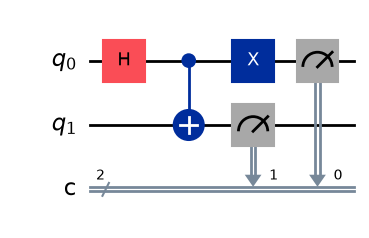

In [7]:
qc_modified = QuantumCircuit(2, 2)

# Start with the same Bell-state circuit
qc_modified.h(0)
qc_modified.cx(0, 1)

# Add exactly one gate to modify the correlation
qc_modified.x(0)

# Measure both qubits
qc_modified.measure([0, 1], [0, 1])

# Display the modified circuit
qc_modified.draw('mpl')

In [8]:
job_modified = simulator.run(qc_modified, shots=100)
result_modified = job_modified.result()

counts_modified = result_modified.get_counts()

print("Modified circuit results:", counts_modified)
print("Total shots:", sum(counts_modified.values()))

Modified circuit results: {'01': 48, '10': 52}
Total shots: 100


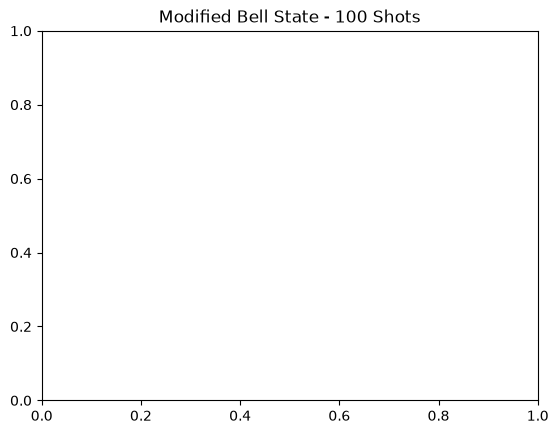

In [9]:
plot_histogram(counts_modified)
plt.title("Modified Bell State - 100 Shots")
plt.show()

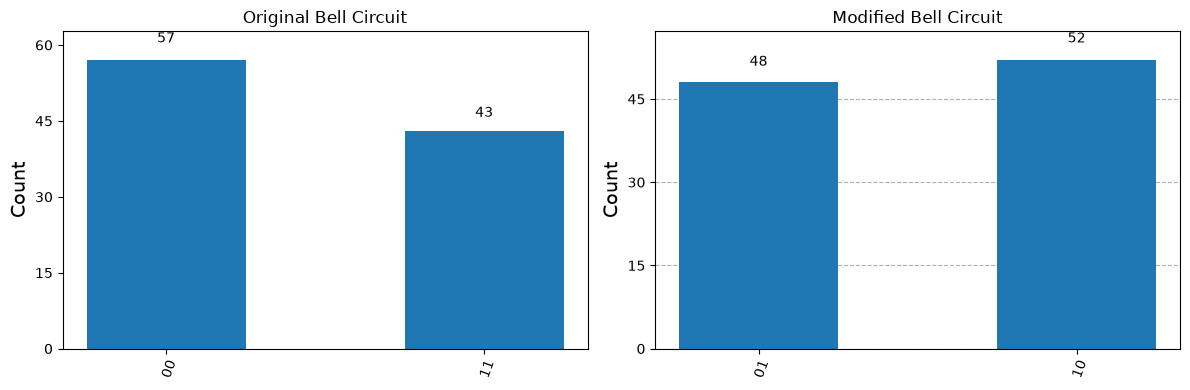

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_histogram(counts_original, ax=axes[0])
axes[0].set_title("Original Bell Circuit")

plot_histogram(counts_modified, ax=axes[1])
axes[1].set_title("Modified Bell Circuit")

plt.tight_layout()
plt.show()

In [11]:
print("Original Bell Circuit:")
for outcome in ['00', '01', '10', '11']:
    count = counts_original.get(outcome, 0)
    print(f"{outcome}: {count} shots ({count}%)")

print("\nModified Bell Circuit:")
for outcome in ['00', '01', '10', '11']:
    count = counts_modified.get(outcome, 0)
    print(f"{outcome}: {count} shots ({count}%)")

Original Bell Circuit:
00: 57 shots (57%)
01: 0 shots (0%)
10: 0 shots (0%)
11: 43 shots (43%)

Modified Bell Circuit:
00: 0 shots (0%)
01: 48 shots (48%)
10: 52 shots (52%)
11: 0 shots (0%)
